# 04 — Classification: Healthy vs Severe OSA (men)

**Input:** `../data/processed/OSA_extreme_male.xlsx` (output of `src/01_data_preparation.py`): 278 men, Healthy (IAH ≤ 10) or Severe (IAH ≥ 30)
**Output:** results tables in `../results/`, figures in `../figures/`

**Question:** can a model tell a severe OSA patient from a healthy one using only age, weight, height, neck circumference and BMI?

**Why men only and extreme cases only?** (course choice, slide 21) Men and women have different typical body measurements (EDA figure 02), and removing intermediate patients gives a clear boundary to learn.

**Evaluation method — nested, repeated cross-validation.** With only 278 patients, one 80/20 split would give a test set of ~56 patients and a very noisy score. Instead:
- **Outer loop** (evaluation): stratified 5-fold cross-validation, repeated 5 times with different shuffles → 25 test folds; every patient is tested 5 times.
- **Inner loop** (tuning): inside each outer training set, `GridSearchCV` with stratified 5-fold CV chooses the hyperparameters.

The test folds are never used for tuning, so the scores are unbiased, and we get a mean **and a spread** for every metric.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (make_scorer, recall_score, confusion_matrix, roc_curve, roc_auc_score,
                             ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
DATA = Path("../data/processed/OSA_extreme_male.xlsx")
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

## 1. Data
The target is coded **Severe = 1** (the class we want to detect, the "positive" class) and Healthy = 0. Gender is not used: all patients are men.

In [2]:
df = pd.read_excel(DATA)
FEATURES = ["Age", "Weight", "Height", "Cervical", "BMI"]
X = df[FEATURES]
y = (df["OSA"] == "Severe").astype(int)
print(X.shape)
print(df["OSA"].value_counts().to_dict())
df[FEATURES + ["IAH", "OSA"]].groupby("OSA").mean().round(1)

(278, 5)
{'Healthy': 141, 'Severe': 137}


,Age,Weight,Height,Cervical,BMI,IAH
OSA,,,,,,
Healthy,44.0,86.0,175.9,40.8,27.8,5.0
Severe,51.2,99.0,175.4,43.6,32.1,45.5


## 2. Metrics
| Metric | Meaning | Why it matters here |
|---|---|---|
| **Sensitivity** (recall of Severe) | share of severe patients detected | missing a severe patient is the worst error in screening |
| **Specificity** (recall of Healthy) | share of healthy patients correctly recognised | avoids sending healthy people to a costly PSG |
| **Accuracy** | share of correct predictions | fine here because the classes are balanced (141 vs 137) |
| **ROC AUC** | probability that a random severe patient gets a higher score than a random healthy one | summarises performance over all decision thresholds (0.5 = chance, 1 = perfect) |

In [3]:
SCORING = {
    "Accuracy": "accuracy",
    "Sensitivity": make_scorer(recall_score, pos_label=1),
    "Specificity": make_scorer(recall_score, pos_label=0),
    "ROC AUC": "roc_auc",
}

## 3. Models and hyperparameters
| Model | Idea | Hyperparameters tuned |
|---|---|---|
| Baseline | always predicts the majority class | – |
| Logistic regression (L2) | linear score → sigmoid → probability of Severe | C (inverse of the penalty strength) |
| Logistic regression (L1, Lasso) | same, with a penalty that can set coefficients to 0 | C |
| Naive Bayes (Gaussian) | Bayes' rule, assuming independent Gaussian features in each class | – |
| KNN | majority class of the k most similar patients | k |
| SVM (RBF kernel) | maximum-margin boundary, non-linear through the kernel | C, gamma |
| Decision tree | if/then rules | max_depth, min_samples_leaf |
| Random Forest | majority vote of many trees (bagging) | max_depth, min_samples_leaf |
| XGBoost | trees added one by one to correct previous errors (boosting) | n_estimators, max_depth, learning_rate |

In [4]:
scaled = lambda m: Pipeline([("scale", StandardScaler()), ("model", m)])
plain = lambda m: Pipeline([("model", m)])

MODELS = {
    "Baseline (majority)": (plain(DummyClassifier(strategy="most_frequent")), {}),
    "Logistic (L2)": (scaled(LogisticRegression(max_iter=5000)), {"model__C": [0.01, 0.1, 1, 10]}),
    "Logistic (L1)": (scaled(LogisticRegression(penalty="l1", solver="liblinear", max_iter=5000)),
                      {"model__C": [0.01, 0.1, 1, 10]}),
    "Naive Bayes": (plain(GaussianNB()), {}),
    "KNN": (scaled(KNeighborsClassifier()), {"model__n_neighbors": [5, 11, 21, 31]}),
    "SVM (RBF)": (scaled(SVC()), {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.05]}),
    "Decision tree": (plain(DecisionTreeClassifier(random_state=SEED)),
                      {"model__max_depth": [2, 3, 4], "model__min_samples_leaf": [5, 15]}),
    "Random Forest": (plain(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
                      {"model__max_depth": [3, 5, None], "model__min_samples_leaf": [3, 10]}),
    "XGBoost": (plain(XGBClassifier(random_state=SEED, n_jobs=-1, subsample=0.8, eval_metric="logloss")),
                {"model__n_estimators": [100, 300], "model__max_depth": [2, 3], "model__learning_rate": [0.03, 0.1]}),
}

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

def tuned(pipe, grid):
    return GridSearchCV(pipe, grid, cv=inner_cv, scoring="roc_auc", n_jobs=-1) if grid else pipe

## 4. Nested repeated cross-validation
For each model: 25 outer test folds × (inner grid search on the training part). Each score below is the mean over the 25 test folds, with its standard deviation.

In [5]:
fold_scores, rows = [], []
for name, (pipe, grid) in MODELS.items():
    cvres = cross_validate(tuned(pipe, grid), X, y, cv=outer_cv, scoring=SCORING, n_jobs=-1)
    r = {"Model": name}
    for m in SCORING:
        s = cvres[f"test_{m}"]
        r[m] = s.mean(); r[f"{m} std"] = s.std()
        fold_scores += [{"Model": name, "Metric": m, "Score": v} for v in s]
    rows.append(r)

results = pd.DataFrame(rows).sort_values("ROC AUC", ascending=False).reset_index(drop=True)
results.to_csv(RES / "classification_nested_cv_results.csv", index=False)
fold_scores = pd.DataFrame(fold_scores)

show = results[["Model"]].copy()
for m in SCORING:
    show[m] = results[m].map("{:.2f}".format) + " ± " + results[f"{m} std"].map("{:.2f}".format)
show

,Model,Accuracy,Sensitivity,Specificity,ROC AUC
0,SVM (RBF),0.71 ± 0.05,0.68 ± 0.10,0.74 ± 0.07,0.79 ± 0.04
1,Random Forest,0.72 ± 0.04,0.74 ± 0.05,0.70 ± 0.06,0.79 ± 0.04
2,Logistic (L2),0.70 ± 0.04,0.67 ± 0.08,0.73 ± 0.06,0.79 ± 0.03
3,Logistic (L1),0.70 ± 0.04,0.68 ± 0.08,0.71 ± 0.07,0.78 ± 0.03
4,Naive Bayes,0.68 ± 0.05,0.54 ± 0.08,0.81 ± 0.06,0.78 ± 0.04
5,KNN,0.71 ± 0.04,0.70 ± 0.09,0.72 ± 0.06,0.78 ± 0.04
6,XGBoost,0.72 ± 0.04,0.74 ± 0.05,0.70 ± 0.06,0.78 ± 0.03
7,Decision tree,0.68 ± 0.05,0.68 ± 0.12,0.68 ± 0.11,0.74 ± 0.06
8,Baseline (majority),0.51 ± 0.01,0.00 ± 0.00,1.00 ± 0.00,0.50 ± 0.00


## 5. Comparison of the models
Each box shows the distribution of the score over the 25 outer test folds. Overlapping boxes mean the difference between two models is within the variability due to the data split.

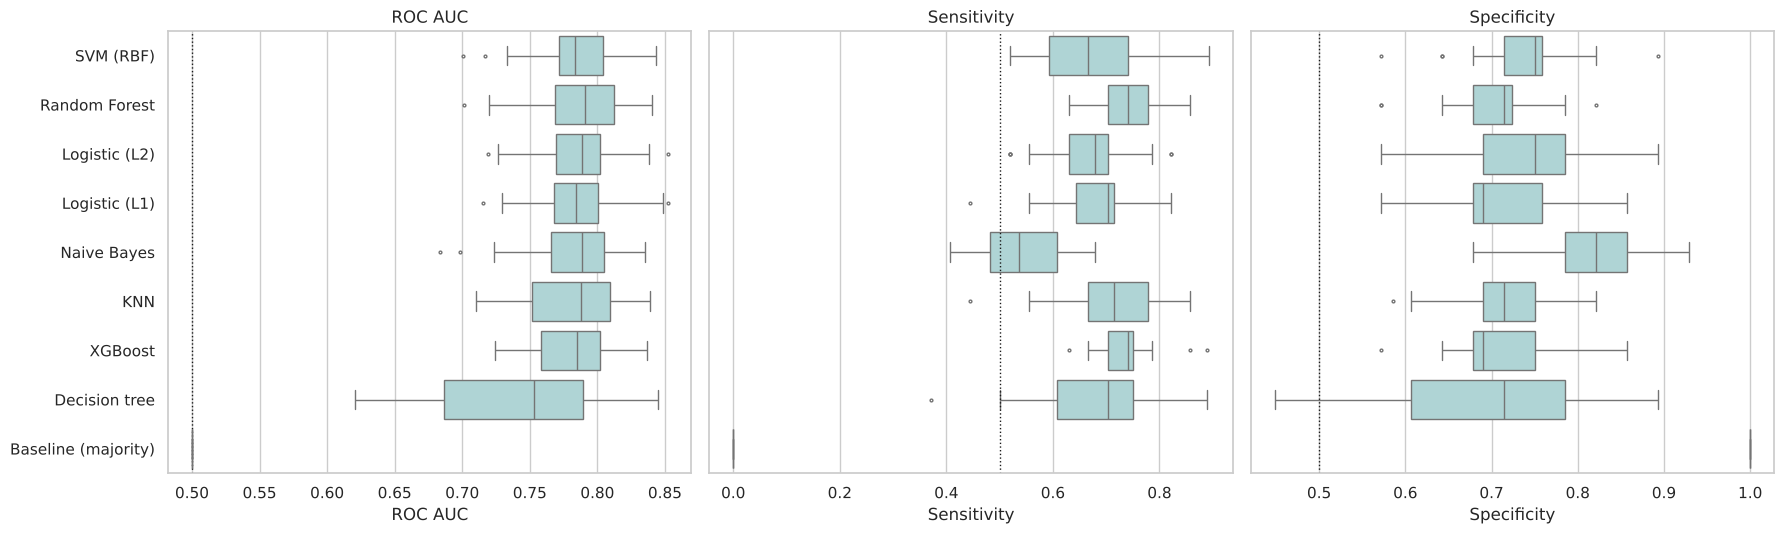

In [6]:
order = results["Model"].tolist()
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for ax, m in zip(axes, ["ROC AUC", "Sensitivity", "Specificity"]):
    sns.boxplot(data=fold_scores[fold_scores.Metric == m], x="Score", y="Model", order=order, ax=ax,
                color="#a8dadc", fliersize=2)
    ax.set(title=m, xlabel=m, ylabel="")
    ax.axvline(0.5, color="k", ls=":", lw=1)
plt.tight_layout(); plt.savefig(FIG / "clf_01_model_comparison.png", dpi=200); plt.show()

## 6. Confusion matrices and ROC curves
To look at individual predictions, every patient gets an **out-of-fold** prediction: the prediction made by a model that did not see this patient during training (stratified 5-fold, with tuning inside each fold).

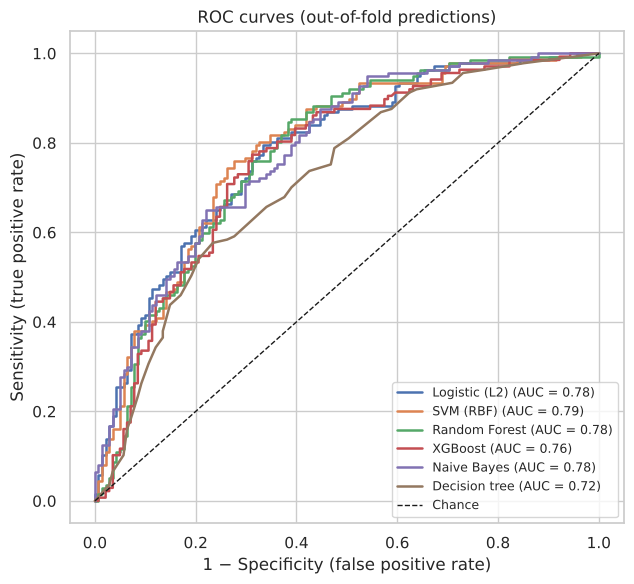

In [7]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SHOW = ["Logistic (L2)", "SVM (RBF)", "Random Forest", "XGBoost", "Naive Bayes", "Decision tree"]
oof_scores = {}
for name in SHOW:
    pipe, grid = MODELS[name]
    method = "decision_function" if name == "SVM (RBF)" else "predict_proba"
    p = cross_val_predict(tuned(pipe, grid), X, y, cv=cv5, method=method, n_jobs=-1)
    oof_scores[name] = p[:, 1] if p.ndim == 2 else p

fig, ax = plt.subplots(figsize=(6.5, 6))
for name, s in oof_scores.items():
    fpr, tpr, _ = roc_curve(y, s)
    ax.plot(fpr, tpr, lw=1.8, label=f"{name} (AUC = {roc_auc_score(y, s):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set(xlabel="1 − Specificity (false positive rate)", ylabel="Sensitivity (true positive rate)",
       title="ROC curves (out-of-fold predictions)")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "clf_02_roc_curves.png", dpi=200); plt.show()

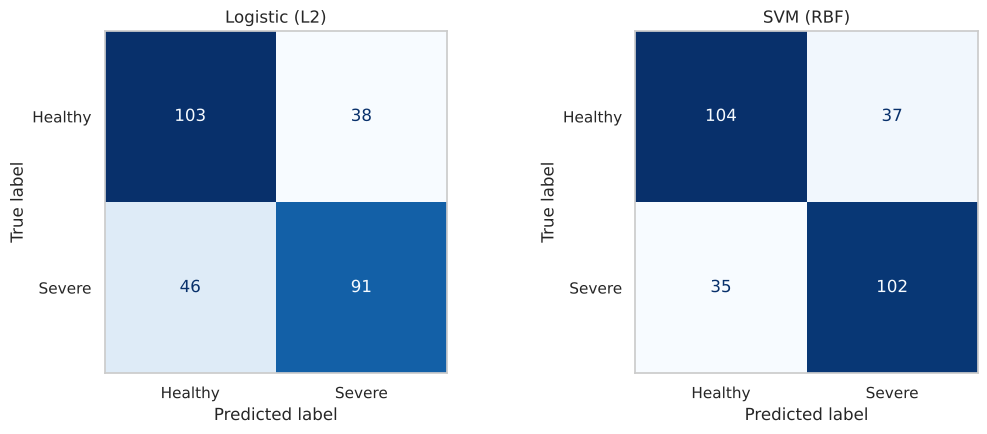

In [8]:
best = results.iloc[0]["Model"] if results.iloc[0]["Model"] in SHOW else "Logistic (L2)"
pairs = [("Logistic (L2)", oof_scores["Logistic (L2)"] >= 0.5)]
if best != "Logistic (L2)":
    thr = 0 if best == "SVM (RBF)" else 0.5
    pairs.append((best, oof_scores[best] >= thr))

fig, axes = plt.subplots(1, len(pairs), figsize=(5.5 * len(pairs), 4.5))
axes = np.atleast_1d(axes)
for ax, (name, pred) in zip(axes, pairs):
    ConfusionMatrixDisplay(confusion_matrix(y, pred.astype(int)), display_labels=["Healthy", "Severe"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name); ax.grid(False)
plt.tight_layout(); plt.savefig(FIG / "clf_03_confusion_matrices.png", dpi=200); plt.show()

## 7. Choosing the decision threshold: sensitivity vs specificity
By default a patient is classified Severe when P(Severe) ≥ 0.5. For screening we may prefer to **detect more severe patients**, at the cost of more false alarms. Lowering the threshold moves along the ROC curve.

In [9]:
s = oof_scores["Logistic (L2)"]
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (s >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    rows.append({"Threshold": t, "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
                 "Severe missed": fn, "Healthy sent to PSG": fp})
thresholds = pd.DataFrame(rows)
thresholds.to_csv(RES / "classification_thresholds_logistic.csv", index=False)
thresholds.round(2)

,Threshold,Sensitivity,Specificity,Severe missed,Healthy sent to PSG
0,0.3,0.97,0.30,4,98
1,0.4,0.87,0.52,18,68
2,0.5,0.66,0.73,46,38
3,0.6,0.43,0.89,78,15
4,0.7,0.26,0.94,101,8


## 8. Interpretation
**a) Logistic regression coefficients (odds ratios).** Fitted on all 278 patients with standardised inputs. An odds ratio of 2 means: +1 standard deviation of the variable doubles the odds of being Severe (other variables fixed). The L1 model shows which variables survive the penalty.

In [10]:
coefs = {}
for name in ["Logistic (L2)", "Logistic (L1)"]:
    pipe, grid = MODELS[name]
    g = GridSearchCV(pipe, grid, cv=inner_cv, scoring="roc_auc").fit(X, y)
    coefs[name] = g.best_estimator_.named_steps["model"].coef_[0]
    print(f"{name}: best C = {g.best_params_['model__C']}")
coef_table = pd.DataFrame(coefs, index=FEATURES)
coef_table["Odds ratio (L2)"] = np.exp(coef_table["Logistic (L2)"])
coef_table.round(2)

Logistic (L2): best C = 0.1
Logistic (L1): best C = 0.1


,Logistic (L2),Logistic (L1),Odds ratio (L2)
Age,0.57,0.45,1.77
Weight,0.36,0.11,1.43
Height,-0.04,0.00,0.96
Cervical,0.36,0.33,1.43
BMI,0.35,0.41,1.42


**b) Permutation importance (Random Forest, held-out folds).** For each of 5 folds, the model is trained on 4/5 of the patients; then each variable is shuffled in the held-out fold and the drop in ROC AUC is measured.

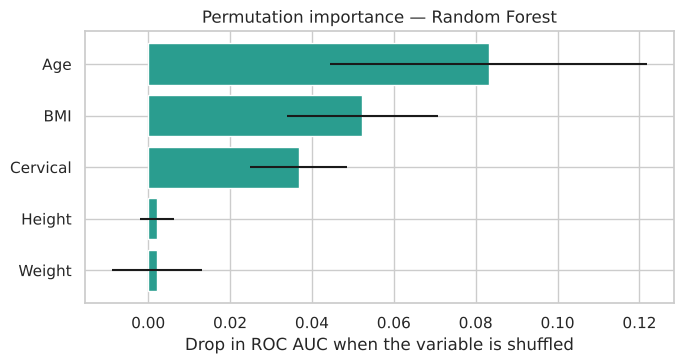

,Variable,AUC drop,std
0,Age,0.083,0.039
4,BMI,0.052,0.018
3,Cervical,0.037,0.012
2,Height,0.002,0.004
1,Weight,0.002,0.011


In [11]:
pipe, grid = MODELS["Random Forest"]
imps = []
for tr, te in cv5.split(X, y):
    m = tuned(pipe, grid).fit(X.iloc[tr], y.iloc[tr])
    r = permutation_importance(m, X.iloc[te], y.iloc[te], scoring="roc_auc", n_repeats=20, random_state=SEED)
    imps.append(r.importances_mean)
imps = np.array(imps)
imp = pd.DataFrame({"Variable": FEATURES, "AUC drop": imps.mean(0), "std": imps.std(0)}).sort_values("AUC drop", ascending=False)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp["Variable"], imp["AUC drop"], xerr=imp["std"], color="#2a9d8f")
ax.invert_yaxis()
ax.set(xlabel="Drop in ROC AUC when the variable is shuffled", title="Permutation importance — Random Forest")
plt.tight_layout(); plt.savefig(FIG / "clf_04_permutation_importance.png", dpi=200); plt.show()
imp.round(3)

**c) A readable decision tree.** A depth-3 tree trained on all patients, to show the kind of rules a doctor could follow (for illustration; its cross-validated performance is in the table above).

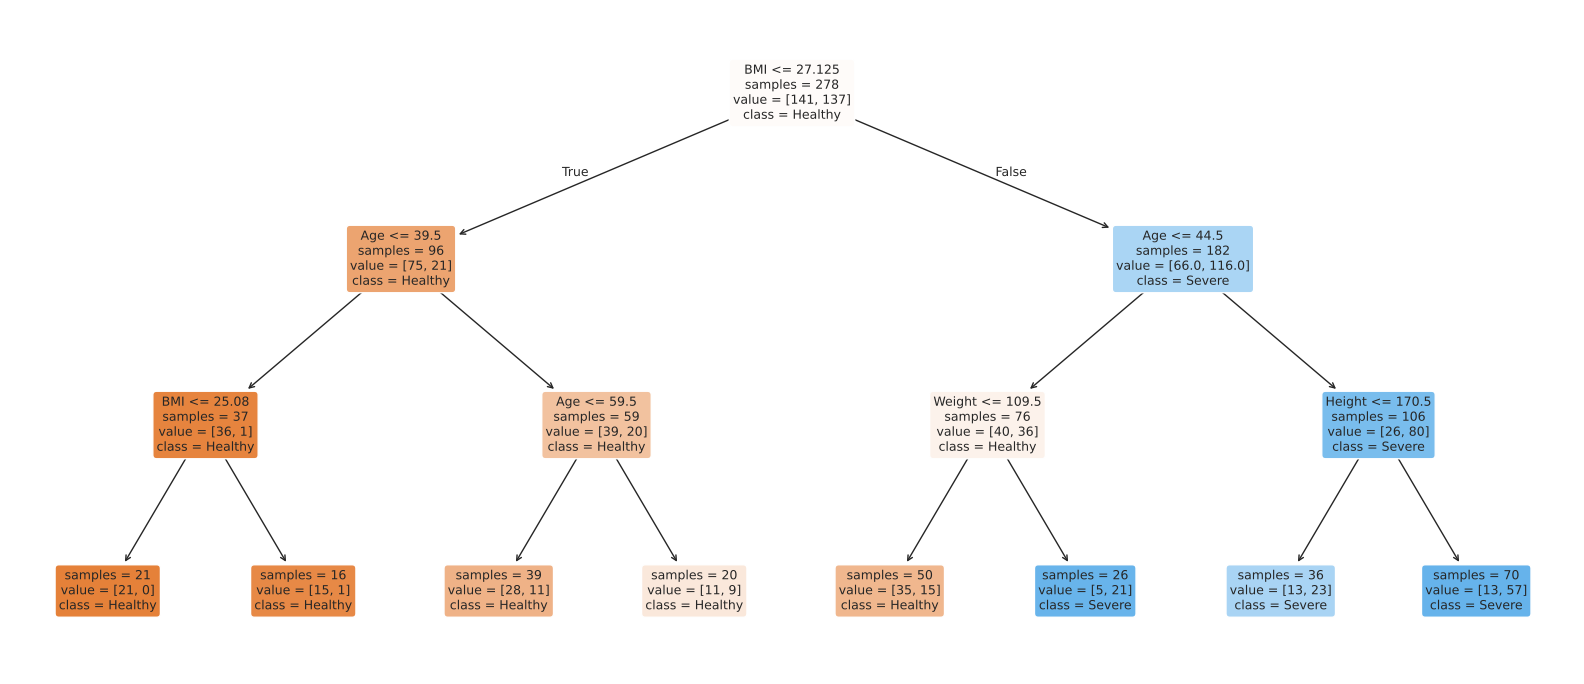

In [12]:
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, random_state=SEED).fit(X, y)
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree, feature_names=FEATURES, class_names=["Healthy", "Severe"], filled=True, rounded=True,
          impurity=False, proportion=False, fontsize=9, ax=ax)
plt.tight_layout(); plt.savefig(FIG / "clf_05_decision_tree.png", dpi=200); plt.show()

## 9. Conclusions
*(to be written in the report from the outputs above)*